<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 1. Aspectos generales

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Aplica segmentacion de clientes con **K-Means** sobre las variables RFM
(Recency, Frequency, Monetary) calculadas a partir del merge en capa **silver**.

Flujo: `silver/merge_pyspark` ---> limpieza ---> calculo RFM ---> K-Means ---> `gold/hym_kmeans`

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, avg, count, sum as spark_sum
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml import Pipeline
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

In [2]:
# Inicializar SparkSession
spark = SparkSession.builder \
    .appName("HYM_KMeans") \
    .config("spark.sql.adaptive.enabled", "true") \
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true") \
    .config("spark.driver.memory", "4g") \
    .config("spark.executor.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "50") \
    .config("spark.memory.fraction", "0.8") \
    .getOrCreate()

spark.sparkContext.setCheckpointDir("/tmp/spark_checkpoint")
spark

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 2. Rutas de capas

In [3]:
SILVER = "./silver"
GOLD   = "./gold"

import os
os.makedirs(GOLD, exist_ok=True)

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 3. Carga desde capa silver

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Lee el DataFrame unificado desde `silver/merge_pyspark` y filtra registros con `age` nulo o cero,
que corresponden a clientes sin informacion demografica valida.

In [4]:
%%time
df_raw = spark.read.parquet(f"{SILVER}/merge_pyspark")
df_raw.createOrReplaceTempView("customer_transactions")

df_clean = spark.sql("""
    SELECT
        customer_id,
        article_id,
        Fecha,
        price,
        sales_channel_id,
        product_type_name,
        product_group_name,
        colour_group_name,
        department_name,
        index_name,
        garment_group_name,
        fashion_news_frequency,
        age
    FROM customer_transactions
    WHERE age IS NOT NULL
      AND age > 0
""")

df_clean.createOrReplaceTempView("clean_transactions")
print(f"Registros tras limpieza: {df_clean.count():,}")

Registros tras limpieza: 31,648,066
CPU times: user 2.03 ms, sys: 5.56 ms, total: 7.6 ms
Wall time: 4.36 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 4. Calculo de variables RFM

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Calcula las tres dimensiones del modelo **RFM** en una unica pasada agregada por cliente:

- **Frequency**: numero total de transacciones del cliente.
- **Sold** (Monetary): suma total de precio pagado.
- **Days** (Recency): dias entre la ultima y penultima compra del cliente,
  calculados con una ventana `LAG` ordenada por fecha.

In [5]:
%%time
retail = spark.sql("""
WITH ranked AS (
    SELECT
        customer_id,
        price,
        Fecha,
        LAG(Fecha) OVER (PARTITION BY customer_id ORDER BY Fecha) AS prev_fecha,
        ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY Fecha DESC) AS rnum
    FROM clean_transactions
),
lastbuy AS (
    SELECT customer_id, DATEDIFF(Fecha, prev_fecha) AS Days
    FROM ranked
    WHERE rnum = 1 AND prev_fecha IS NOT NULL
),
freq_amount AS (
    SELECT
        customer_id,
        COUNT(1)      AS Frequency,
        SUM(price)    AS Monetary
    FROM clean_transactions
    GROUP BY customer_id
)
SELECT
    f.customer_id,
    CAST(f.Frequency AS INT)   AS Frequency,
    CAST(f.Monetary      AS FLOAT) AS Monetary,
    CAST(l.Days      AS INT)   AS Recency
FROM freq_amount f
INNER JOIN lastbuy l ON f.customer_id = l.customer_id
""")

retail.createOrReplaceTempView("retail")
retail = retail.checkpoint()
print(f"Clientes con datos RFM: {retail.count():,}")

Clientes con datos RFM: 907,262
CPU times: user 35 ms, sys: 11.6 ms, total: 46.6 ms
Wall time: 25.1 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 5. Estadisticas descriptivas

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Revision de la distribucion de las variables antes de aplicar el modelo.
Se usa `describe()` de Spark para evitar traer todo el DataFrame al driver.

In [6]:
retail.select("Frequency", "Monetary", "Recency").describe().show()

+-------+-----------------+------------------+------------------+
|summary|        Frequency|          Monetary|           Recency|
+-------+-----------------+------------------+------------------+
|  count|           907262|            907262|            907262|
|   mean|33.20348146400929|0.9252677800357777| 95.09396954793654|
| stddev|44.83247195210684|1.3844537868924416|118.65969244183664|
|    min|                2|      0.0033559322|                 1|
|    max|             1895|         57.676407|               731|
+-------+-----------------+------------------+------------------+



In [7]:
# Calcular percentiles por columna con approxQuantile (no materializa en driver)
for col_name in ["Frequency", "Monetary", "Recency"]:
    q = retail.approxQuantile(col_name, [0.25, 0.50, 0.75, 0.95], 0.01)
    print(f"{col_name}  Q1={q[0]:.1f}  Mediana={q[1]:.1f}  Q3={q[2]:.1f}  P95={q[3]:.1f}")

Frequency  Q1=8.0  Mediana=18.0  Q3=39.0  P95=103.0
Monetary  Q1=0.2  Mediana=0.5  Q3=1.0  P95=2.9
Recency  Q1=14.0  Mediana=47.0  Q3=126.0  P95=337.0


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 6. Analisis de outliers y filtrado

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Calcula los limites de outliers usando el metodo IQR (Tukey) con `approxQuantile`.
Se aplica un filtro conservador: `Frequency <= 1250` para eliminar clientes atipicos
que distorsionarian los centroides del clustering.

In [8]:
def iqr_bounds(df, col_name, k=1.5):
    q1, q3 = df.approxQuantile(col_name, [0.25, 0.75], 0.01)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for col_name in ["Frequency", "Monetary", "Recency"]:
    lb, ub = iqr_bounds(retail, col_name)
    n_out = retail.filter((col(col_name) < lb) | (col(col_name) > ub)).count()
    pct   = n_out / retail.count() * 100
    print(f"{col_name}: outliers={n_out:,} ({pct:.2f}%)  limites=[{lb:.1f}, {ub:.1f}]")

Frequency: outliers=75,628 (8.34%)  limites=[-38.5, 85.5]
Monetary: outliers=84,059 (9.27%)  limites=[-1.0, 2.3]
Recency: outliers=72,255 (7.96%)  limites=[-154.0, 294.0]


In [9]:
df_filter = retail.filter(col("Frequency") <= 1250).checkpoint()
print(f"Clientes tras filtrado: {df_filter.count():,}")
df_filter.select("Frequency", "Monetary", "Recency").describe().show()

Clientes tras filtrado: 907,258
+-------+------------------+------------------+------------------+
|summary|         Frequency|          Monetary|           Recency|
+-------+------------------+------------------+------------------+
|  count|            907258|            907258|            907258|
|   mean| 33.19694728511625|0.9250664201878432|  95.0943821933783|
| stddev|44.722018333688595| 1.380966385046567|118.65979126694863|
|    min|                 2|      0.0033559322|                 1|
|    max|              1237|          49.96717|               731|
+-------+------------------+------------------+------------------+



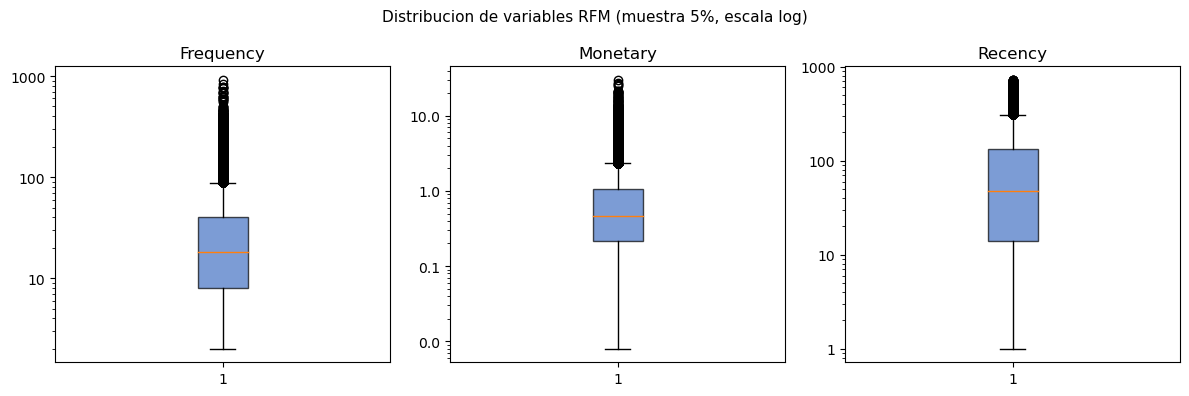

In [10]:
# Boxplot con muestra para no saturar el driver
sample_pd = df_filter.select("Frequency", "Monetary", "Recency").sample(fraction=0.05, seed=42).toPandas()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col_name in zip(axes, ["Frequency", "Monetary", "Recency"]):
    ax.boxplot(sample_pd[col_name].dropna(), vert=True, patch_artist=True,
               boxprops=dict(facecolor="#4472C4", alpha=0.7))
    ax.set_title(col_name)
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
fig.suptitle("Distribucion de variables RFM (muestra 5%, escala log)", fontsize=11)
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 7. Preparacion de features para K-Means

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Ensambla las tres variables en un vector y las escala con `StandardScaler`.
El escalado es necesario porque K-Means usa distancia euclidiana y las magnitudes
de `Sold` (miles) y `Days` (decenas) son muy distintas.

In [11]:
assembler = VectorAssembler(
    inputCols=["Frequency", "Monetary", "Recency"],
    outputCol="features_raw",
    handleInvalid="skip"
)

scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=False
)

pipeline_prep = Pipeline(stages=[assembler, scaler])
prep_model    = pipeline_prep.fit(df_filter)
df_features   = prep_model.transform(df_filter).select("customer_id", "Frequency", "Monetary", "Recency", "features")
df_features   = df_features.checkpoint()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 8. Grafica del codo

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Evalua el **WSSSE** (Within Set Sum of Squared Errors) para k entre 2 y 14.
El punto donde la curva deja de bajar abruptamente indica el k optimo (metodo del codo).

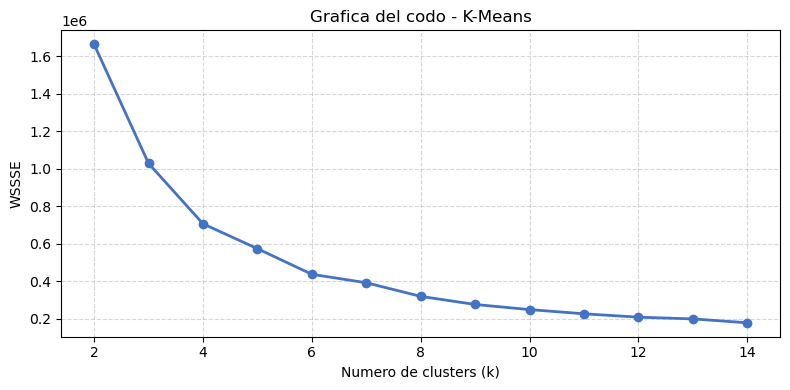

CPU times: user 346 ms, sys: 271 ms, total: 617 ms
Wall time: 47.9 s


In [12]:
%%time
costs = []
K_range = range(2, 15)

for k in K_range:
    km     = KMeans(featuresCol="features", k=k, seed=42, maxIter=20)
    m      = km.fit(df_features)
    costs.append(m.summary.trainingCost)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(K_range), costs, marker="o", color="#4472C4", linewidth=2)
ax.set_xlabel("Numero de clusters (k)")
ax.set_ylabel("WSSSE")
ax.set_title("Grafica del codo - K-Means")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 9. Entrenamiento del modelo final

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Entrena K-Means con el k elegido a partir del analisis del codo (por defecto **k=10**).
El resultado se une al DataFrame con variables RFM para caracterizar cada cluster.

In [13]:
%%time
BEST_K = 10

km_final      = KMeans(featuresCol="features", k=BEST_K, seed=42, maxIter=30)
km_model      = km_final.fit(df_features)
df_clustered  = km_model.transform(df_features)

consolidado = df_clustered.select("customer_id", "Frequency", "Monetary", "Recency", "prediction")
consolidado = consolidado.withColumnRenamed("prediction", "cluster")
consolidado.show(5)

+--------------------+---------+-----------+-------+-------+
|         customer_id|Frequency|   Monetary|Recency|cluster|
+--------------------+---------+-----------+-------+-------+
|0000d6c053fc8f938...|        7| 0.14057627|      3|      0|
|000114c6996ef5703...|       18| 0.33698305|    486|      3|
|0002d2ef78ec29c03...|       43|  1.3823221|     45|      6|
|000346516dd355b40...|       20| 0.45686442|     39|      0|
|00078b3110954a85c...|        2|0.042338982|      9|      0|
+--------------------+---------+-----------+-------+-------+
only showing top 5 rows

CPU times: user 30.4 ms, sys: 11.4 ms, total: 41.7 ms
Wall time: 3.77 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 10. Perfil de clusters

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Calcula las medias de las variables RFM por cluster para interpretar
el comportamiento comercial de cada grupo.

In [14]:
perfil = (
    consolidado.groupBy("cluster")
    .agg(
        count("customer_id").alias("n_clientes"),
        avg("Frequency").alias("freq_media"),
        avg("Monetary").alias("Monetary_media"),
        avg("Recency").alias("Recency_media")
    )
    .orderBy("cluster")
)
perfil.show()

+-------+----------+------------------+-------------------+------------------+
|cluster|n_clientes|        freq_media|     Monetary_media|     Recency_media|
+-------+----------+------------------+-------------------+------------------+
|      0|    320775|11.890025718961889|0.30694473885149925|  30.6885979268958|
|      1|    158874|15.619994461019424|0.41746155716691524|148.89745962209045|
|      2|     14492|196.75489925476126|  6.039006876955367|26.719224399668782|
|      3|     33689| 9.877615838997892| 0.2715461321154144|492.38021312594617|
|      4|     86109| 74.19690160145862|  2.057242050403367| 43.47510713165871|
|      5|     37524|123.35116192303592|  3.608785058447273| 34.28155313932417|
|      6|    166668| 39.33150934792522| 1.0346685040042198|36.086789305685556|
|      7|      4539| 316.1260189469046| 10.073389225737275|18.788940295219213|
|      8|     83851|14.473935910126295|0.39483307207875146|294.11029087309635|
|      9|       737|  565.697421981004| 18.975604889

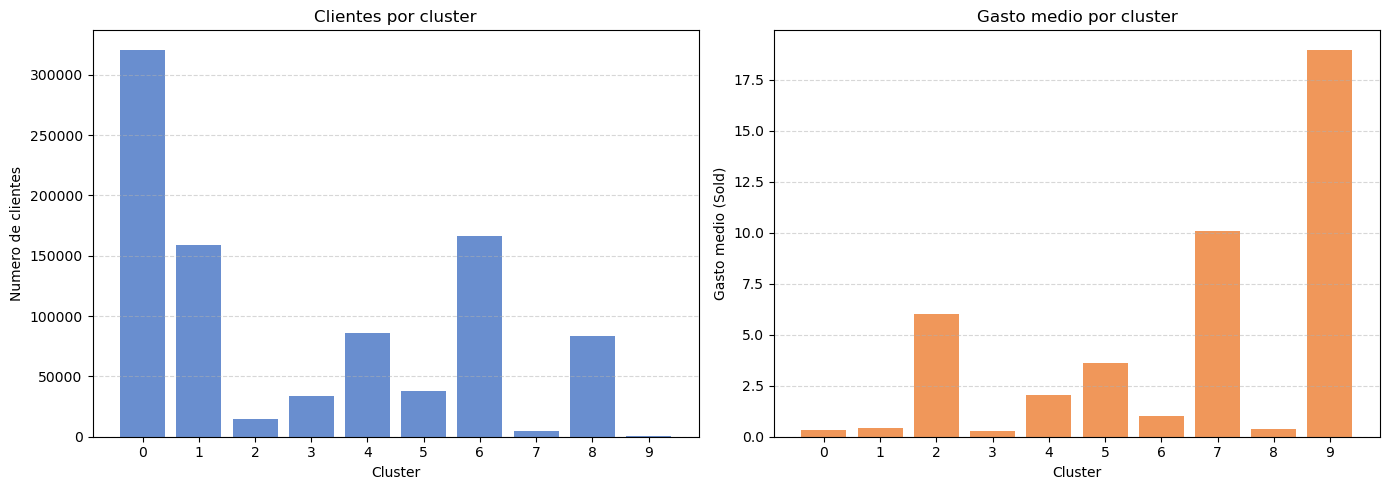

In [15]:
# Grafico de barras del tamano de cada cluster
perfil_pd = perfil.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribucion de clientes
axes[0].bar(perfil_pd["cluster"].astype(str), perfil_pd["n_clientes"], color="#4472C4", alpha=0.8)
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Numero de clientes")
axes[0].set_title("Clientes por cluster")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Gasto medio por cluster
axes[1].bar(perfil_pd["cluster"].astype(str), perfil_pd["Monetary_media"], color="#ED7D31", alpha=0.8)
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Gasto medio (Sold)")
axes[1].set_title("Gasto medio por cluster")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 11. Escritura en capa gold

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Guarda el DataFrame con la asignacion de clusters en `gold/hym_kmeans`.

In [16]:
consolidado.write.mode("overwrite").parquet(f"{GOLD}/hym_kmeans")
print("Escritura en gold/hym_kmeans completada")

# Verificacion
spark.read.parquet(f"{GOLD}/hym_kmeans").select("cluster").groupBy("cluster").count().orderBy("cluster").show()

Escritura en gold/hym_kmeans completada
+-------+------+
|cluster| count|
+-------+------+
|      0|320775|
|      1|158874|
|      2| 14492|
|      3| 33689|
|      4| 86109|
|      5| 37524|
|      6|166668|
|      7|  4539|
|      8| 83851|
|      9|   737|
+-------+------+



In [17]:
spark.stop()